# 💡 AI for IoT – Practical 1: Fire Alarm Detection

**Goal:** build a binary classifier that predicts whether an IoT smoke detector's **Fire Alarm** is ON (`1`) or OFF (`0`) from its environmental sensor readings.

- **Core task:** Logistic Regression (with mandatory feature scaling)
- **Bonus:** XGBoost and a comparison with Logistic Regression

**Dataset:** [Kaggle – Smoke Detection Dataset](https://www.kaggle.com/datasets/deepcontractor/smoke-detection-dataset)
> On Kaggle: *Add Input → Datasets → search "smoke detection dataset" (deepcontractor)*. The loader below finds the CSV automatically.

## 1. Setup – Import libraries

In [1]:
# Data handling
import os
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning (scikit-learn)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

# Bonus model
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # fixed seed for reproducible results

## 2. Load and inspect the data

In [2]:
# Find the CSV inside the attached Kaggle input folder (falls back to the current folder when run locally)
csv_path = None
for root in ["/kaggle/input", "."]:
    for dirpath, _, files in os.walk(root):
        for f in files:
            if f.lower() == "smoke_detection_iot.csv":
                csv_path = os.path.join(dirpath, f)
                break
        if csv_path:
            break
    if csv_path:
        break

assert csv_path is not None, "smoke_detection_iot.csv not found - attach the dataset to the notebook."
print("Loading:", csv_path)

df = pd.read_csv(csv_path)
print("Shape:", df.shape)
df.head()

Loading: .\smoke_detection_iot.csv
Shape: (62630, 16)


,Unnamed: 0,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
0,0,1654733331,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0,0
1,1,1654733332,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,1,0
2,2,1654733333,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,2,0
3,3,1654733334,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,3,0
4,4,1654733335,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,4,0


In [3]:
# Column types, non-null counts and memory usage
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62630 entries, 0 to 62629
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      62630 non-null  int64  
 1   UTC             62630 non-null  int64  
 2   Temperature[C]  62630 non-null  float64
 3   Humidity[%]     62630 non-null  float64
 4   TVOC[ppb]       62630 non-null  int64  
 5   eCO2[ppm]       62630 non-null  int64  
 6   Raw H2          62630 non-null  int64  
 7   Raw Ethanol     62630 non-null  int64  
 8   Pressure[hPa]   62630 non-null  float64
 9   PM1.0           62630 non-null  float64
 10  PM2.5           62630 non-null  float64
 11  NC0.5           62630 non-null  float64
 12  NC1.0           62630 non-null  float64
 13  NC2.5           62630 non-null  float64
 14  CNT             62630 non-null  int64  
 15  Fire Alarm      62630 non-null  int64  
dtypes: float64(8), int64(8)
memory usage: 7.6 MB


In [4]:
# Missing values per column
df.isnull().sum()

Unnamed: 0        0
UTC               0
Temperature[C]    0
Humidity[%]       0
TVOC[ppb]         0
eCO2[ppm]         0
Raw H2            0
Raw Ethanol       0
Pressure[hPa]     0
PM1.0             0
PM2.5             0
NC0.5             0
NC1.0             0
NC2.5             0
CNT               0
Fire Alarm        0
dtype: int64

In [5]:
# Summary statistics of every sensor
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,62630.0,3.131450e+04,18079.868017,0.000000e+00,1.565725e+04,3.131450e+04,4.697175e+04,6.262900e+04
UTC,62630.0,1.654792e+09,110002.488078,1.654712e+09,1.654743e+09,1.654762e+09,1.654778e+09,1.655130e+09
Temperature[C],62630.0,1.597042e+01,14.359576,-2.201000e+01,1.099425e+01,2.013000e+01,2.540950e+01,5.993000e+01
Humidity[%],62630.0,4.853950e+01,8.865367,1.074000e+01,4.753000e+01,5.015000e+01,5.324000e+01,7.520000e+01
TVOC[ppb],62630.0,1.942058e+03,7811.589055,0.000000e+00,1.300000e+02,9.810000e+02,1.189000e+03,6.000000e+04
eCO2[ppm],62630.0,6.700210e+02,1905.885439,4.000000e+02,4.000000e+02,4.000000e+02,4.380000e+02,6.000000e+04
Raw H2,62630.0,1.294245e+04,272.464305,1.066800e+04,1.283000e+04,1.292400e+04,1.310900e+04,1.380300e+04
Raw Ethanol,62630.0,1.975426e+04,609.513156,1.531700e+04,1.943500e+04,1.950100e+04,2.007800e+04,2.141000e+04
Pressure[hPa],62630.0,9.386276e+02,1.331344,9.308520e+02,9.387000e+02,9.388160e+02,9.394180e+02,9.398610e+02
PM1.0,62630.0,1.005943e+02,922.524245,0.000000e+00,1.280000e+00,1.810000e+00,2.090000e+00,1.433369e+04


### Handling missing data
The `.isnull().sum()` output above shows whether there are any missing values (this dataset normally has none).
To keep the notebook robust anyway, any missing numeric value is replaced with the **median** of its column. The median is less affected than the mean by the extreme sensor spikes in this data.

In [6]:
missing_before = df.isnull().sum().sum()
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())   # median imputation
df = df.dropna()                                            # drop anything non-numeric that is still missing
print(f"Missing values before: {missing_before} | after: {df.isnull().sum().sum()}")

# Duplicated rows
print("Duplicated rows:", df.duplicated().sum())

Missing values before: 0 | after: 0


Duplicated rows: 0


### Target distribution (class balance)

Fire Alarm
1    44757
0    17873
Name: count, dtype: int64

Proportions:
 Fire Alarm
1    0.715
0    0.285
Name: count, dtype: float64


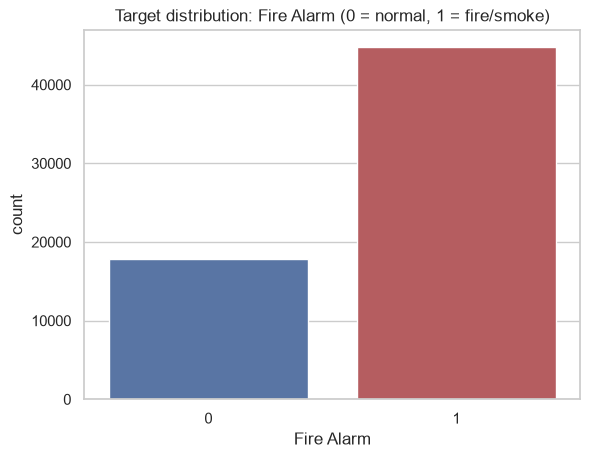

In [7]:
counts = df["Fire Alarm"].value_counts()
print(counts)
print("\nProportions:\n", (counts / len(df)).round(3))

ax = sns.countplot(x="Fire Alarm", data=df, palette=["#4C72B0", "#C44E52"])
ax.set_title("Target distribution: Fire Alarm (0 = normal, 1 = fire/smoke)")
plt.show()

The classes are **imbalanced**: about 71.5% of the samples have the alarm ON. This is why we:
- use a **stratified** train/test split, so both sets keep the same class ratio;
- report Precision, Recall and F1, not only Accuracy.

### Correlation between sensors and the target

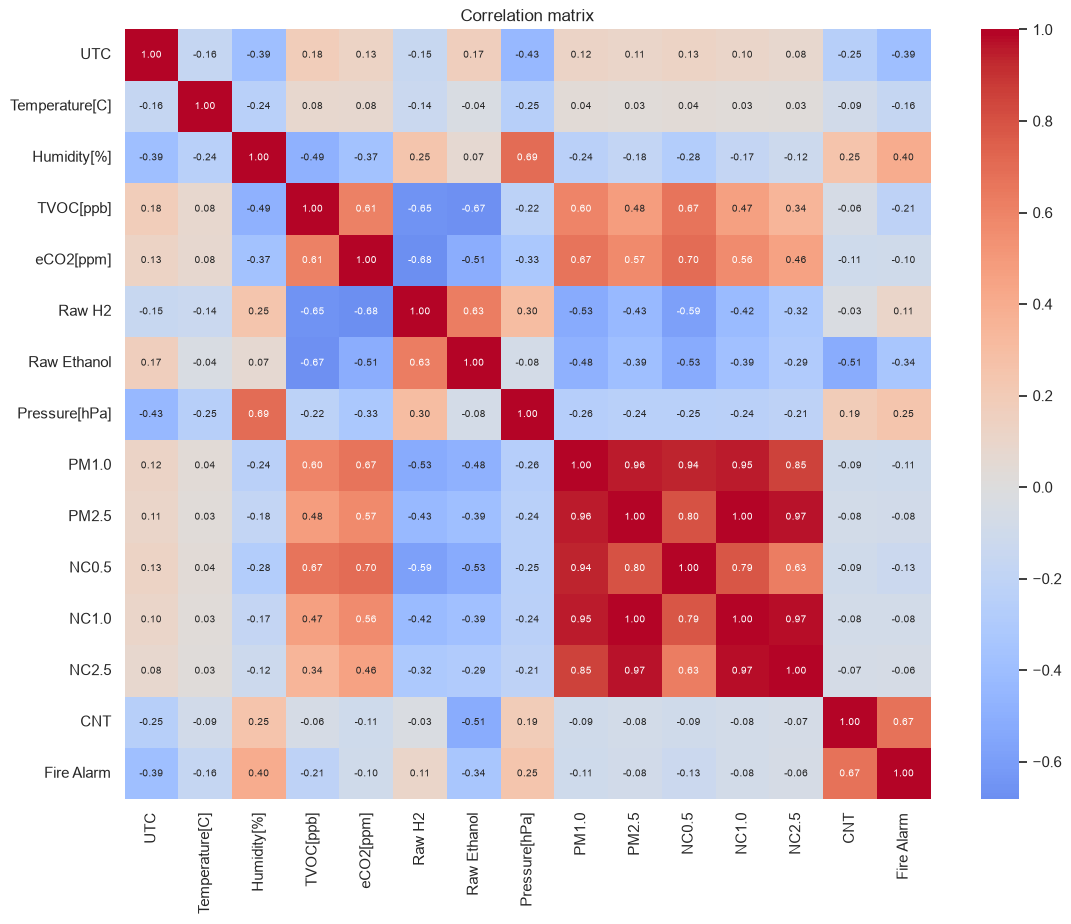

In [8]:
plt.figure(figsize=(13, 10))
corr = df.drop(columns=[c for c in ["Unnamed: 0"] if c in df.columns]).corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix")
plt.show()

## 3. Define features (X) and target (y)

Columns that are **not physical sensor readings** are removed:
- `Unnamed: 0`: the row index of the CSV;
- `UTC`: the timestamp. The fire tests were recorded in separate sessions, so the time alone would reveal the label;
- `CNT`: a sample counter that restarts at each recording session. It also leaks information about the session and is not a measurement.

Keeping these columns would make the model learn *when* a sample was recorded, not *what the sensors measure*. That would not work on a real deployed device.

In [9]:
TARGET = "Fire Alarm"
DROP_COLS = ["Unnamed: 0", "UTC", "CNT"]

X = df.drop(columns=[TARGET] + [c for c in DROP_COLS if c in df.columns])
y = df[TARGET]

# XGBoost forbids '[', ']' and '<' in feature names -> "Temperature[C]" becomes "Temperature_C"
X.columns = X.columns.str.replace("[", "_", regex=False).str.replace("]", "", regex=False)

print("Features used:", list(X.columns))
print("X shape:", X.shape, "| y shape:", y.shape)

Features used: ['Temperature_C', 'Humidity_%', 'TVOC_ppb', 'eCO2_ppm', 'Raw H2', 'Raw Ethanol', 'Pressure_hPa', 'PM1.0', 'PM2.5', 'NC0.5', 'NC1.0', 'NC2.5']
X shape: (62630, 12) | y shape: (62630,)


## 4. Split the data (80% train / 20% test)

The data is split **before** scaling. The scaler then learns the mean and standard deviation from the training set only, so no information from the test set leaks into training.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          # 20% for testing
    stratify=y,              # keep the same class ratio in both sets
    random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (50104, 12) | Test: (12526, 12)


## 5. Feature scaling (mandatory for Logistic Regression)

The sensors use very different units and ranges. For example, `Pressure_hPa` is around 939, while `TVOC_ppb` goes up to 60,000.
Logistic Regression is trained by gradient-based optimisation and uses a single regularisation penalty for all weights, so unscaled features would dominate.
`StandardScaler` rescales each feature to mean 0 and standard deviation 1.

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on the training data only
X_test_scaled  = scaler.transform(X_test)        # apply the same transform to the test data

print("Train means (≈0):", X_train_scaled.mean(axis=0).round(2))
print("Train stds  (≈1):", X_train_scaled.std(axis=0).round(2))

Train means (≈0): [-0. -0. -0. -0.  0. -0.  0.  0. -0.  0.  0. -0.]
Train stds  (≈1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 6. Train the Logistic Regression model

In [12]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

## 7. Predictions and evaluation

In [13]:
def evaluate(name, y_true, y_pred):
    # Compute the four required metrics and return them as a dict
    res = {
        "Model": name,
        "Accuracy":  metrics.accuracy_score(y_true, y_pred),
        "Precision": metrics.precision_score(y_true, y_pred),
        "Recall":    metrics.recall_score(y_true, y_pred),
        "F1-Score":  metrics.f1_score(y_true, y_pred),
    }
    for k, v in res.items():
        if k != "Model":
            print(f"{k:<10}: {v:.4f}")
    return res

def plot_confusion(name, y_true, y_pred, cmap="Blues"):
    # Show the confusion matrix with readable class labels
    cm = metrics.confusion_matrix(y_true, y_pred)
    disp = metrics.ConfusionMatrixDisplay(cm, display_labels=["No Fire (0)", "Fire (1)"])
    disp.plot(cmap=cmap, values_format="d")
    plt.title(f"Confusion Matrix – {name}")
    plt.grid(False)
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    return cm

In [14]:
y_pred_lr = log_reg.predict(X_test_scaled)

print("=== Logistic Regression ===")
res_lr = evaluate("Logistic Regression", y_test, y_pred_lr)
print("\nDetailed report:\n", metrics.classification_report(y_test, y_pred_lr, digits=4))

=== Logistic Regression ===
Accuracy  : 0.8951
Precision : 0.9090
Recall    : 0.9482
F1-Score  : 0.9281

Detailed report:
               precision    recall  f1-score   support

           0     0.8545    0.7622    0.8057      3575
           1     0.9090    0.9482    0.9281      8951

    accuracy                         0.8951     12526
   macro avg     0.8817    0.8552    0.8669     12526
weighted avg     0.8934    0.8951    0.8932     12526



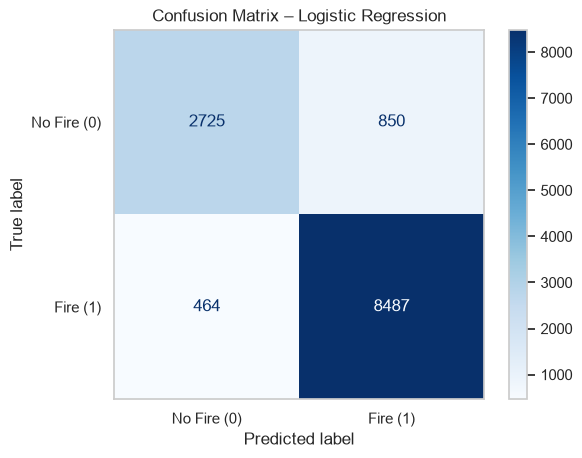

TN=2725  FP=850  FN=464  TP=8487


In [15]:
cm_lr = plot_confusion("Logistic Regression", y_test, y_pred_lr, cmap="Blues")

### Which sensors matter most for Logistic Regression?
Because the features are standardised, the size of each coefficient can be compared directly with the others.

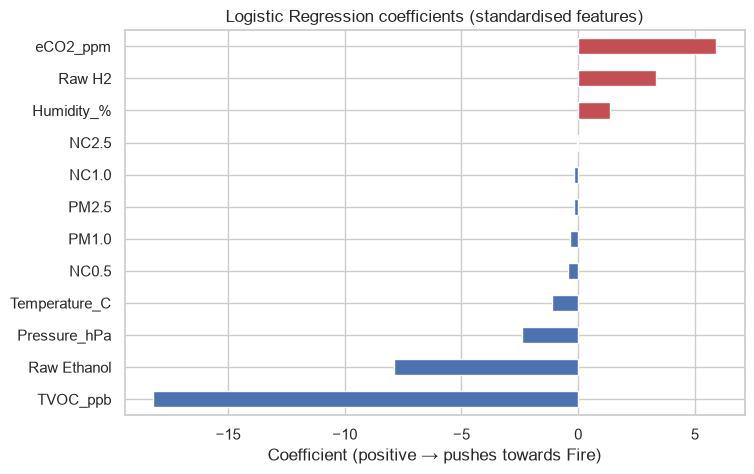

In [16]:
coefs = pd.Series(log_reg.coef_[0], index=X.columns).sort_values()
coefs.plot(kind="barh", figsize=(8, 5), color=np.where(coefs > 0, "#C44E52", "#4C72B0"))
plt.title("Logistic Regression coefficients (standardised features)")
plt.xlabel("Coefficient (positive → pushes towards Fire)")
plt.show()

---
# 🏆 Bonus: XGBoost

XGBoost builds an ensemble of decision trees, one after another. Each new tree corrects the errors of the previous ones.
Trees split on threshold values, so they **do not need feature scaling**. We use the raw (unscaled) features with the **same train/test split**, so the comparison is fair.

In [17]:
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgb.fit(X_train, y_train)   # raw features: scaling is not required for trees

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.9
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [18]:
y_pred_xgb = xgb.predict(X_test)

print("=== XGBoost ===")
res_xgb = evaluate("XGBoost", y_test, y_pred_xgb)
print("\nDetailed report:\n", metrics.classification_report(y_test, y_pred_xgb, digits=4))

=== XGBoost ===
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000

Detailed report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      3575
           1     1.0000    1.0000    1.0000      8951

    accuracy                         1.0000     12526
   macro avg     1.0000    1.0000    1.0000     12526
weighted avg     1.0000    1.0000    1.0000     12526



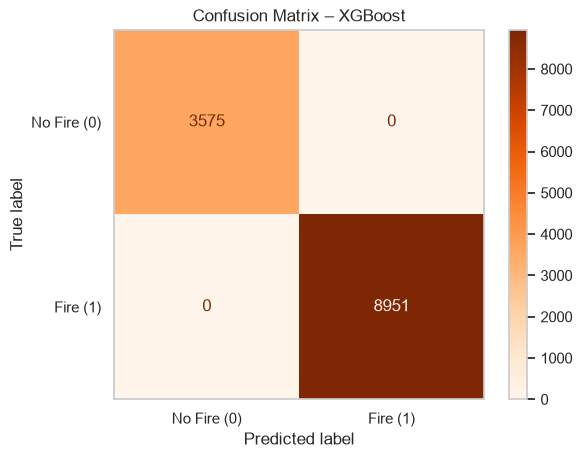

TN=3575  FP=0  FN=0  TP=8951


In [19]:
cm_xgb = plot_confusion("XGBoost", y_test, y_pred_xgb, cmap="Oranges")

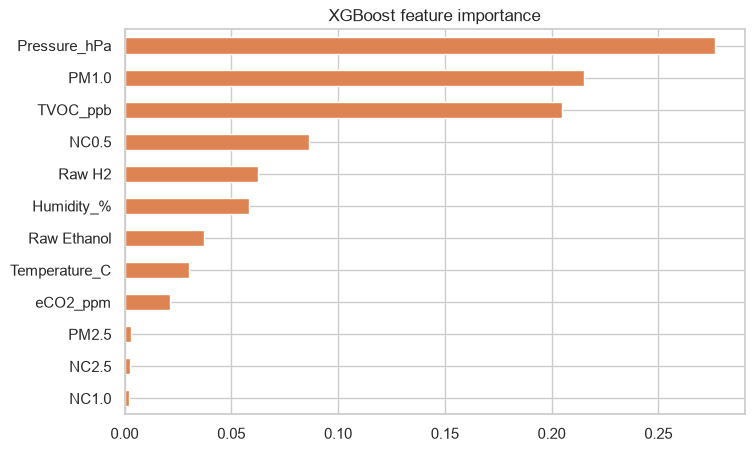

In [20]:
# Feature importance learned by XGBoost
imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 5), color="#DD8452")
plt.title("XGBoost feature importance")
plt.show()

## Model comparison

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.8951,0.9090,0.9482,0.9281
XGBoost,1.0000,1.0000,1.0000,1.0000


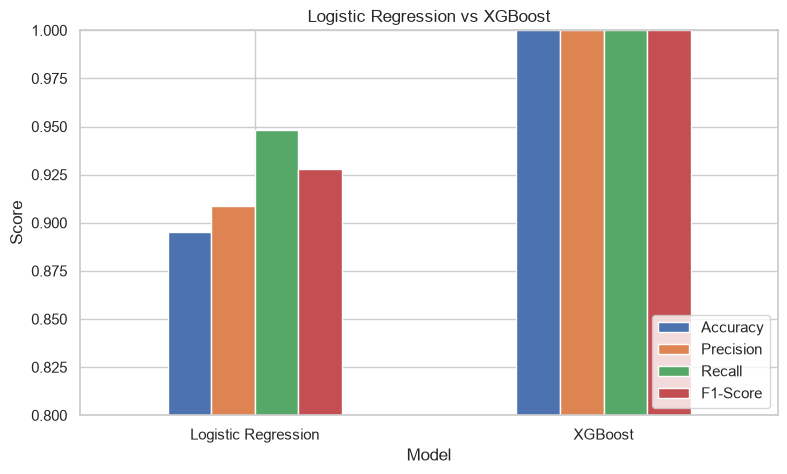

False Negatives (missed fires) – Logistic Regression: 464 | XGBoost: 0
Higher Recall: XGBoost


In [21]:
results = pd.DataFrame([res_lr, res_xgb]).set_index("Model")
display(results.style.format("{:.4f}").highlight_max(axis=0, color="#c6efce"))

results.plot(kind="bar", figsize=(9, 5), ylim=(min(0.8, results.values.min() - 0.02), 1.0), rot=0)
plt.title("Logistic Regression vs XGBoost")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.show()

fn_lr, fn_xgb = cm_lr[1, 0], cm_xgb[1, 0]
print(f"False Negatives (missed fires) – Logistic Regression: {fn_lr} | XGBoost: {fn_xgb}")
print("Higher Recall:", results["Recall"].idxmax())

### Training / inference time (simplicity vs complexity)

In [22]:
import time

def timeit(fn, n=5):
    t = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t) / n * 1000  # ms

timing = pd.DataFrame({
    "Train (ms)": [
        timeit(lambda: LogisticRegression(max_iter=1000).fit(X_train_scaled, y_train), n=3),
        timeit(lambda: XGBClassifier(**xgb.get_params()).fit(X_train, y_train), n=1),
    ],
    "Predict test set (ms)": [
        timeit(lambda: log_reg.predict(X_test_scaled)),
        timeit(lambda: xgb.predict(X_test)),
    ],
}, index=["Logistic Regression", "XGBoost"])
timing.round(2)

,Train (ms),Predict test set (ms)
Logistic Regression,202.39,0.63
XGBoost,883.49,13.14


---
# 🔧 Improvement 1: a better Logistic Regression

The baseline Logistic Regression misses 464 fires on the test set. Two simple changes help it a lot.

**a) `log1p` transform of the skewed sensors.** `TVOC`, `eCO2`, `PM` and `NC` are 0 most of the time but can jump to tens of thousands during a fire.
On such a scale a linear model only "sees" the extreme values. `log1p(x) = log(1 + x)` compresses the large values and spreads out the small ones.

**b) Lower decision threshold.** By default the model says "fire" when `P(fire) ≥ 0.5`. In a safety system a missed fire costs much more than a false alarm, so we lower the threshold.
The threshold is chosen **on the training set only**, using 5-fold cross-validated probabilities. We take the highest threshold that still gives **Recall ≥ 0.99**. The test set is never used to choose it.

Both transforms are wrapped in a `Pipeline`, so the scaler and the log transform are always fitted on training data only.

In [23]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import cross_val_predict, StratifiedKFold

# Skewed, non-negative sensors that get the log transform
SKEWED = ["TVOC_ppb", "eCO2_ppm", "PM1.0", "PM2.5", "NC0.5", "NC1.0", "NC2.5"]

def make_lr_log():
    # log1p on the skewed sensors -> StandardScaler on all features -> Logistic Regression
    log_step = ColumnTransformer([("log", FunctionTransformer(np.log1p), SKEWED)], remainder="passthrough")
    return make_pipeline(log_step, StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

# Skewness before / after the log transform (0 = symmetric)
pd.DataFrame({"skew before": X_train[SKEWED].skew(), "skew after log1p": np.log1p(X_train[SKEWED]).skew()}).round(1)

,skew before,skew after log1p
TVOC_ppb,6.8,-1.0
eCO2_ppm,12.8,5.6
PM1.0,10.7,6.2
PM2.5,14.1,6.4
NC0.5,10.0,4.4
NC1.0,14.4,6.4
NC2.5,17.7,8.5


In [24]:
# (a) Logistic Regression + log1p, default threshold 0.5
lr_log = make_lr_log().fit(X_train, y_train)   # the pipeline scales internally -> raw features as input
y_pred_lr_log = lr_log.predict(X_test)

print("=== Logistic Regression + log1p (threshold 0.5) ===")
res_lr_log = evaluate("LR + log1p", y_test, y_pred_lr_log)

=== Logistic Regression + log1p (threshold 0.5) ===
Accuracy  : 0.9369
Precision : 0.9380
Recall    : 0.9763
F1-Score  : 0.9568


Chosen threshold: 0.376  (instead of 0.5)


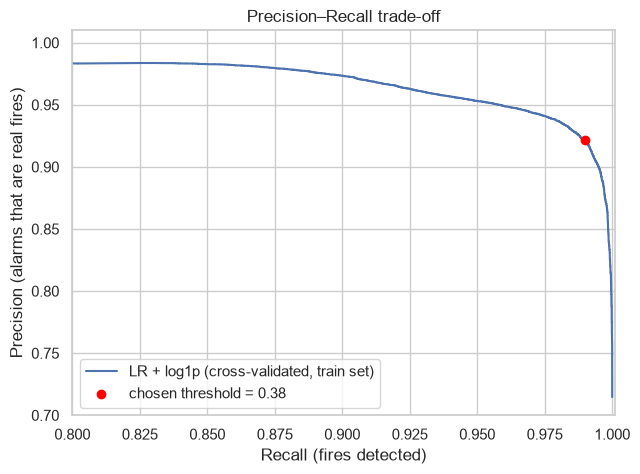

In [25]:
# (b) Choose the threshold on the TRAINING set with cross-validated probabilities
TARGET_RECALL = 0.99
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
proba_cv = cross_val_predict(make_lr_log(), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

prec_cv, rec_cv, thr_cv = metrics.precision_recall_curve(y_train, proba_cv)
best_threshold = thr_cv[np.where(rec_cv[:-1] >= TARGET_RECALL)[0][-1]]   # highest threshold with Recall >= 0.99
print(f"Chosen threshold: {best_threshold:.3f}  (instead of 0.5)")

# Precision-Recall curve showing the trade-off
plt.figure(figsize=(7, 5))
plt.plot(rec_cv, prec_cv, label="LR + log1p (cross-validated, train set)")
i = np.where(thr_cv == best_threshold)[0][0]
plt.scatter(rec_cv[i], prec_cv[i], color="red", zorder=3, label=f"chosen threshold = {best_threshold:.2f}")
plt.xlabel("Recall (fires detected)")
plt.ylabel("Precision (alarms that are real fires)")
plt.title("Precision–Recall trade-off")
plt.xlim(0.8, 1.001); plt.ylim(0.7, 1.01)
plt.legend()
plt.show()

=== Logistic Regression + log1p (threshold 0.38) ===
Accuracy  : 0.9313
Precision : 0.9221
Recall    : 0.9873
F1-Score  : 0.9535


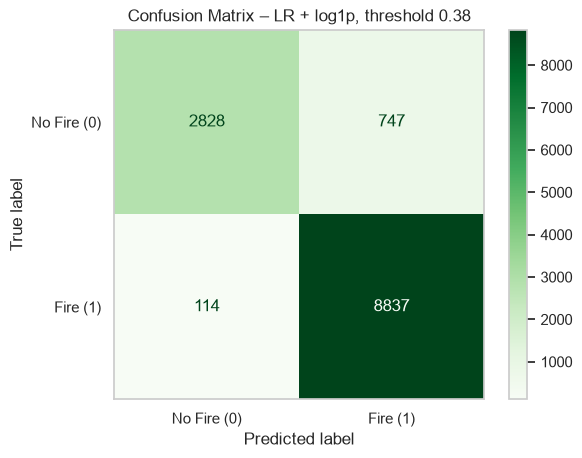

TN=2828  FP=747  FN=114  TP=8837


In [26]:
# Apply the chosen threshold to the TEST set
y_pred_lr_thr = (lr_log.predict_proba(X_test)[:, 1] >= best_threshold).astype(int)

print(f"=== Logistic Regression + log1p (threshold {best_threshold:.2f}) ===")
res_lr_thr = evaluate(f"LR + log1p + thr {best_threshold:.2f}", y_test, y_pred_lr_thr)
cm_lr_thr = plot_confusion(f"LR + log1p, threshold {best_threshold:.2f}", y_test, y_pred_lr_thr, cmap="Greens")

In [27]:
# All models on the random 80/20 split
results_all = pd.DataFrame([res_lr, res_lr_log, res_lr_thr, res_xgb]).set_index("Model")
results_all["Missed fires (FN)"] = [metrics.confusion_matrix(y_test, p)[1, 0] for p in [y_pred_lr, y_pred_lr_log, y_pred_lr_thr, y_pred_xgb]]
results_all["False alarms (FP)"] = [metrics.confusion_matrix(y_test, p)[0, 1] for p in [y_pred_lr, y_pred_lr_log, y_pred_lr_thr, y_pred_xgb]]
results_all.round(4)

,Accuracy,Precision,Recall,F1-Score,Missed fires (FN),False alarms (FP)
Model,,,,,,
Logistic Regression,0.8951,0.9090,0.9482,0.9281,464,850
LR + log1p,0.9369,0.9380,0.9763,0.9568,212,578
LR + log1p + thr 0.38,0.9313,0.9221,0.9873,0.9535,114,747
XGBoost,1.0000,1.0000,1.0000,1.0000,0,0


---
# 🔬 Improvement 2: a realistic evaluation (split by recording session)

**Problem with the random split.** The sensors record **one sample per second**. Two consecutive samples are almost identical, and a random split puts one in the training set and the other in the test set.
The model can then "recognise" a test sample instead of really generalising. This explains XGBoost's Recall of 1.0000 on the random split.

**Solution.** The `CNT` counter restarts at 0 at the beginning of each **recording session**, so we can detect the sessions.
We then use **Leave-One-Session-Out** cross-validation: we train on all sessions except one and test on the session that was left out, and we repeat this for every session.
Every prediction is made by a model that **never saw that session**, which is like installing the detector in a new place.

In [28]:
from sklearn.model_selection import LeaveOneGroupOut

# A new session starts each time the CNT counter goes back down
session = (df["CNT"].diff() < 0).cumsum().loc[X.index]

sessions_info = df.loc[X.index].assign(session=session).groupby("session").agg(
    samples=("Fire Alarm", "size"),
    fire_ratio=("Fire Alarm", "mean"),
    start=("UTC", "min"),
    end=("UTC", "max"),
)
sessions_info["start"] = pd.to_datetime(sessions_info["start"], unit="s")
sessions_info["end"] = pd.to_datetime(sessions_info["end"], unit="s")
sessions_info.round(3)

,samples,fire_ratio,start,end
session,,,,
0,24994,0.873,2022-06-09 00:08:51,2022-06-09 07:05:24
1,24994,0.873,2022-06-09 07:55:43,2022-06-09 14:52:16
2,1154,0.971,2022-06-10 23:16:45,2022-06-10 23:35:58
3,5744,0.000,2022-06-08 18:16:27,2022-06-08 19:52:10
4,5744,0.000,2022-06-13 12:45:08,2022-06-13 14:20:51


The dataset contains **5 sessions**:
- sessions 3 and 4 are almost entirely **normal** conditions (2 fire samples out of 5,744, and 2 out of 5,744), so their test fold measures **false alarms**;
- sessions 0, 1 and 2 are mostly **fire/smoke** (fire ratio 0.873, 0.873 and 0.971), so their test fold mostly measures **missed fires**.

### Proof of memorisation: a 1-Nearest-Neighbour "model"
A 1-NN classifier does not learn any rule. For each test sample it **copies the label of the most similar training sample**.
If 1-NN gets an almost perfect score, the test set mostly contains near-copies of training samples.
We also measure the **time gap** between each test sample and the training sample it copies.

In [29]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=1).fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

print("=== 1-NN (copy the nearest training sample) ===")
res_knn = evaluate("1-NN", y_test, y_pred_knn)

# Which training sample was copied, and how far away in time was it recorded?
_, nn_idx = knn.kneighbors(X_test_scaled, n_neighbors=1)
nn_rows = X_train.index[nn_idx[:, 0]]
time_gap = np.abs(df.loc[X_test.index, "UTC"].values - df.loc[nn_rows, "UTC"].values)
same_session = (session.loc[X_test.index].values == session.loc[nn_rows].values)

print(f"\nMedian time gap to the copied sample : {np.median(time_gap):.0f} s")
print(f"Copied sample recorded within 5 s    : {(time_gap <= 5).mean():.1%}")
print(f"Copied sample from the same session  : {same_session.mean():.1%}")

=== 1-NN (copy the nearest training sample) ===
Accuracy  : 0.9989
Precision : 0.9988
Recall    : 0.9997
F1-Score  : 0.9992



Median time gap to the copied sample : 3 s
Copied sample recorded within 5 s    : 51.3%
Copied sample from the same session  : 99.5%


### Leave-One-Session-Out results
The out-of-fold predictions of the 5 folds are put together, and the metrics are computed on the whole dataset (62,630 samples, 44,757 fires).

In [30]:
models_loso = {
    "Logistic Regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "LR + log1p": make_lr_log,
    "XGBoost": lambda: XGBClassifier(**xgb.get_params()),
    "1-NN": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1)),
}

logo = LeaveOneGroupOut()
loso_results, per_session = [], []
for name, make_model in models_loso.items():
    y_oof = np.zeros(len(y), dtype=int)          # out-of-fold predictions
    for train_idx, test_idx in logo.split(X, y, groups=session):
        model = make_model().fit(X.iloc[train_idx], y.iloc[train_idx])
        y_oof[test_idx] = model.predict(X.iloc[test_idx])
        per_session.append({"Model": name, "Test session": session.iloc[test_idx[0]],
                            "Accuracy": metrics.accuracy_score(y.iloc[test_idx], y_oof[test_idx])})
    print(f"--- {name} (Leave-One-Session-Out) ---")
    res = evaluate(name, y, y_oof)
    tn, fp, fn, tp = metrics.confusion_matrix(y, y_oof).ravel()
    res.update({"Missed fires (FN)": fn, "False alarms (FP)": fp})
    loso_results.append(res)
    print()

loso_df = pd.DataFrame(loso_results).set_index("Model")
loso_df.round(4)

--- Logistic Regression (Leave-One-Session-Out) ---
Accuracy  : 0.5741
Precision : 0.8457
Recall    : 0.4943
F1-Score  : 0.6239



--- LR + log1p (Leave-One-Session-Out) ---
Accuracy  : 0.7411
Precision : 0.8539
Recall    : 0.7694
F1-Score  : 0.8095



--- XGBoost (Leave-One-Session-Out) ---
Accuracy  : 0.8690
Precision : 0.9448
Recall    : 0.8674
F1-Score  : 0.9044



--- 1-NN (Leave-One-Session-Out) ---
Accuracy  : 0.5778
Precision : 0.8843
Recall    : 0.4708
F1-Score  : 0.6144



,Accuracy,Precision,Recall,F1-Score,Missed fires (FN),False alarms (FP)
Model,,,,,,
Logistic Regression,0.5741,0.8457,0.4943,0.6239,22635,4036
LR + log1p,0.7411,0.8539,0.7694,0.8095,10319,5894
XGBoost,0.8690,0.9448,0.8674,0.9044,5935,2270
1-NN,0.5778,0.8843,0.4708,0.6144,23686,2757


In [31]:
# Accuracy on each held-out session
per_session_df = pd.DataFrame(per_session).pivot(index="Test session", columns="Model", values="Accuracy")
per_session_df["fire_ratio"] = sessions_info["fire_ratio"]
per_session_df.round(3)

Model,1-NN,LR + log1p,Logistic Regression,XGBoost,fire_ratio
Test session,,,,,
0,0.269,0.792,0.271,0.901,0.873
1,0.725,0.759,0.734,0.907,0.873
2,0.029,0.029,0.168,0.029,0.971
3,1.000,0.922,0.967,0.605,0.000
4,0.968,0.402,0.887,1.000,0.000


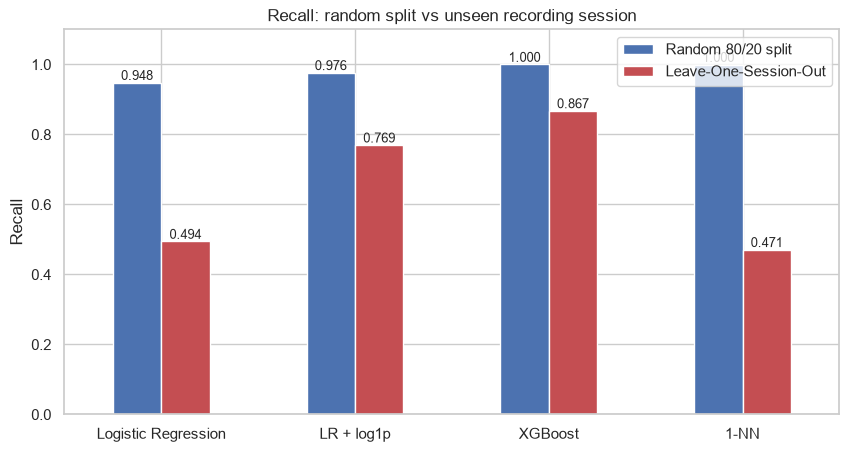

In [32]:
# Recall: random split vs session split
compare = pd.DataFrame({
    "Random 80/20 split": [res_lr["Recall"], res_lr_log["Recall"], res_xgb["Recall"], res_knn["Recall"]],
    "Leave-One-Session-Out": loso_df.loc[["Logistic Regression", "LR + log1p", "XGBoost", "1-NN"], "Recall"].values,
}, index=["Logistic Regression", "LR + log1p", "XGBoost", "1-NN"])

ax = compare.plot(kind="bar", figsize=(10, 5), rot=0, color=["#4C72B0", "#C44E52"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=9)
plt.title("Recall: random split vs unseen recording session")
plt.ylabel("Recall")
plt.ylim(0, 1.1)
plt.show()

---
# 📝 Conclusion

Every number below comes from the outputs of this notebook (`random_state = 42`).

### Results summary: random 80/20 split (test set: 12,526 samples, 8,951 real fires)
| Model | Accuracy | Precision | Recall | F1-Score | Missed fires (FN) | False alarms (FP) |
|---|---|---|---|---|---|---|
| Logistic Regression (baseline) | 0.8951 | 0.9090 | **0.9482** | 0.9281 | 464 | 850 |
| LR + log1p | 0.9369 | 0.9380 | 0.9763 | 0.9568 | 212 | 578 |
| LR + log1p + threshold 0.38 | 0.9313 | 0.9221 | **0.9873** | 0.9535 | **114** | 747 |
| XGBoost | 1.0000 | 1.0000 | **1.0000** | 1.0000 | **0** | 0 |

### Results summary: Leave-One-Session-Out (each session tested by a model that never saw it; 62,630 samples, 44,757 fires)
| Model | Accuracy | Precision | Recall | F1-Score | Missed fires (FN) | False alarms (FP) |
|---|---|---|---|---|---|---|
| Logistic Regression (baseline) | 0.5741 | 0.8457 | 0.4943 | 0.6239 | 22,635 | 4,036 |
| LR + log1p | 0.7411 | 0.8539 | 0.7694 | 0.8095 | 10,319 | 5,894 |
| XGBoost | 0.8690 | 0.9448 | **0.8674** | 0.9044 | 5,935 | 2,270 |

### 1. Interpreting the Recall of Logistic Regression
**Recall = TP / (TP + FN)** is the fraction of real fire/smoke events that the model detects.
The baseline Logistic Regression reaches **Recall = 0.9482**. It detects 8,487 of the 8,951 fire samples and **misses 464 of them** (about **5 in every 100 fires**). These missed fires are the *False Negatives* in the bottom-left cell of the confusion matrix.
It also raises 850 false alarms: only 76% of the normal samples are recognised as normal.
The main weakness is the skewed sensor scale, not the linear model itself:
- with a simple **log1p** transform, the missed fires drop from 464 to 212, and the false alarms drop from 850 to 578;
- with the decision threshold **lowered to 0.38** (chosen on training data only), Recall reaches **0.9873** and only **114 fires are missed**, 4.1 times fewer than the baseline. The cost is more false alarms than with log1p alone (747 vs 578), which is still fewer than the baseline (850).

### 2. Why minimising False Negatives is crucial in fire detection
- A **False Negative** means a real fire with no alarm. People are not warned, the fire keeps spreading, and the result can be loss of life or property. This cost is **very high and cannot be undone**.
- A **False Positive** is a false alarm. It is annoying and costly (evacuation, firefighter call-out, users losing trust), but it is **recoverable**.
- For a safety-critical IoT device, **Recall is the most important metric**. Lowering the threshold, as in Improvement 1, is exactly this trade: a small loss of Precision for far fewer missed fires.

### 3. Why XGBoost gets 1.0000 on the random split
- A 1-NN "model" that only copies the label of the most similar training sample already reaches **Accuracy = 0.9989** on the same test set.
- The copied training sample was recorded a median of **3 s** away from the test sample, and within 5 s in **51.3%** of the cases.
- So the random test set mostly contains **near-copies of training samples**: it measures memorisation, not generalisation. This is called **temporal leakage**.
- When 1-NN is tested on a session it has never seen, its Recall drops from 0.9997 to **0.4708**.

### 4. Implications for IoT fire alarm reliability: what the session split shows
- **On a recording session the model has never seen, every model drops sharply.** The baseline Logistic Regression detects only **49.4%** of the fires, LR + log1p 76.9%, and XGBoost **86.7%**.
- **Session 2** (1,154 samples, fire ratio 0.971) is almost completely missed: accuracy 0.029 for LR + log1p and 0.029 for XGBoost. Its sensor readings differ from those of the other sessions. Models trained on a few sessions do not transfer automatically to new conditions.
- The false alarms also depend on the session. XGBoost reaches accuracy 1.000 on normal session 4 but only 0.605 on normal session 3.
- log1p helps Logistic Regression detect more fires on new sessions (Recall 0.4943 → 0.7694), but it raises more false alarms (4,036 → 5,894).
- **Consequence for a real product:** a fire detector must be validated on **new environments** (other rooms, devices, fire types, cooking, steam, sensor drift), not on random samples from the same recordings. More varied training sessions are needed before deployment.

### 5. Limits of this study
- There are only **5 recording sessions**, so the session-based scores depend strongly on which sessions are in the data. They show the order of magnitude, not exact values.
- Sessions 0 and 1 hold 80% of all samples, so they dominate the pooled Leave-One-Session-Out metrics.
- The threshold 0.38 was chosen with cross-validation on a random split, which has the same leakage. On a new session it will probably not give Recall ≥ 0.99.

### 6. Logistic Regression vs XGBoost (Bonus)
| Criterion | Logistic Regression | XGBoost |
|---|---|---|
| **Recall (random split)** | 0.9482 → **0.9873** after log1p + threshold | **1.0000** (inflated by temporal leakage) |
| **Recall (unseen session)** | 0.4943 → 0.7694 with log1p | **0.8674** |
| **Feature scaling** | Required | Not required |
| **Training / inference speed** (measured above) | **Very fast**: a fraction of a second to train, about 1 ms to predict | Several times slower to train and to predict (exact values vary between runs) |
| **Model size / edge deployment** | **Tiny**: one weight per sensor plus a bias. It runs on a microcontroller. | Larger: hundreds of trees. It needs more memory and compute (on an edge gateway or in the cloud, or after model compression). |
| **Interpretability** | **High**: coefficients show the effect of each sensor | Medium: feature importances / SHAP |
| **Non-linear patterns** | Not captured (only partly, with feature engineering such as log1p) | Captured (feature interactions, thresholds) |

**Answer:** **XGBoost has the higher Recall** in both evaluations (1.0000 on the random split, 0.8674 on unseen sessions). It generalises best to new conditions, so it is the most reliable model here.

**Trade-off:** Logistic Regression is simple, fast, interpretable and small enough for a low-power IoT node. With good preprocessing (log1p) and a safety-oriented threshold, it gets close to XGBoost on the random split, but it generalises less well to new environments. XGBoost is more robust, but it uses more compute and memory and is harder to explain.
In a real AIoT system, a common compromise is to run a lightweight model on the device and the stronger XGBoost model on a gateway or in the cloud. Another option is to run XGBoost on the device after compressing it (fewer or shallower trees). In both cases the decision threshold should be tuned for high Recall.